# 03. Hierarchical Model Classification

Test whether family-first classification improves identification of 18 language models using prompt-grouped cross-validation.

## 1. Load data

In [15]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, recall_score,
)
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

train_path = PROJECT_ROOT / "data" / "train.csv"
train_df = pd.read_csv(train_path).reset_index(drop=True)
required = {"text", "model", "prompt_id"}
missing = required - set(train_df.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

X = train_df["text"].fillna("").astype(str)
y = train_df["model"].astype(str)
groups = train_df["prompt_id"]


def get_family(model_name):
    if model_name.startswith("qwen"):
        return "qwen"
    return model_name.split("-")[0]

y_family = y.map(get_family)
family_names = sorted(y_family.unique())
model_names = sorted(y.unique())
folds = list(GroupKFold(n_splits=5).split(X, y, groups))
assert all(set(groups.iloc[tr]).isdisjoint(set(groups.iloc[te])) for tr, te in folds)

def build_char_model(class_weight=None):
    return make_pipeline(
        TfidfVectorizer(
            analyzer="char", ngram_range=(2, 5), min_df=2,
            sublinear_tf=True, max_features=100_000,
        ),
        LinearSVC(C=1.0, max_iter=5000, class_weight=class_weight),
    )

print("Texts:", len(X), "| Prompts:", groups.nunique())
display(y_family.value_counts().rename("count"))

Texts: 2699 | Prompts: 150


model
gpt       750
claude    749
gemini    600
glm       300
qwen      150
kimi      150
Name: count, dtype: int64

## 2. Pairwise Family Classification

Evaluate GLM vs Claude, Kimi vs GPT, and Qwen vs GPT on unseen prompts.

In [16]:
PAIRS = [("glm", "claude"), ("kimi", "gpt"), ("qwen", "gpt")]
pair_rows = []
pair_predictions = {}

for a, b in PAIRS:
    pair_key = f"{a}_vs_{b}"
    mask = y_family.isin([a, b]).to_numpy()
    pair_global_idx = np.flatnonzero(mask)
    # Reuse the original five global folds, restricting indices to this pair.
    oof = np.empty(len(pair_global_idx), dtype=object)
    assigned = np.zeros(len(pair_global_idx), dtype=bool)
    local_pos = pd.Series(np.arange(len(pair_global_idx)), index=pair_global_idx)

    for fold_id, (train_idx, val_idx) in enumerate(folds):
        tr = train_idx[mask[train_idx]]
        te = val_idx[mask[val_idx]]
        if len(te) == 0:
            continue
        clf = build_char_model(class_weight="balanced")
        clf.fit(X.iloc[tr], y_family.iloc[tr])
        pred = clf.predict(X.iloc[te])
        pos = local_pos.loc[te].to_numpy()
        oof[pos] = pred
        assigned[pos] = True
        pair_rows.append({
            "pair": pair_key, "fold": fold_id, "n_test": len(te),
            "balanced_accuracy": balanced_accuracy_score(y_family.iloc[te], pred),
        })

    assert assigned.all()
    truth = y_family.iloc[pair_global_idx].to_numpy()
    pair_predictions[pair_key] = {"true": truth, "pred": oof, "global_indices": pair_global_idx}

pair_fold_scores = pd.DataFrame(pair_rows)
pair_summary = []
for key, res in pair_predictions.items():
    a, b = key.split("_vs_")
    pair_summary.append({
        "pair": key,
        "balanced_accuracy_oof": balanced_accuracy_score(res["true"], res["pred"]),
        "recall_" + a: recall_score(res["true"], res["pred"], labels=[a], average="macro"),
        "recall_" + b: recall_score(res["true"], res["pred"], labels=[b], average="macro"),
        "n": len(res["true"]),
    })

display(pd.DataFrame(pair_summary).round(3))
display(pair_fold_scores.pivot(index="fold", columns="pair", values="balanced_accuracy").round(3))

,pair,balanced_accuracy_oof,recall_glm,recall_claude,n,recall_kimi,recall_gpt,recall_qwen
0,glm_vs_claude,0.578,0.237,0.919,1049,NaN,NaN,NaN
1,kimi_vs_gpt,0.547,NaN,NaN,900,0.107,0.987,NaN
2,qwen_vs_gpt,0.564,NaN,NaN,900,NaN,0.995,0.133


pair,glm_vs_claude,kimi_vs_gpt,qwen_vs_gpt
fold,,,
0,0.545,0.527,0.550
1,0.578,0.560,0.527
2,0.610,0.513,0.563
3,0.588,0.560,0.580
4,0.567,0.573,0.600


### 2.1. Pairwise Confusion Matrices

Row-normalized to compare family recall.

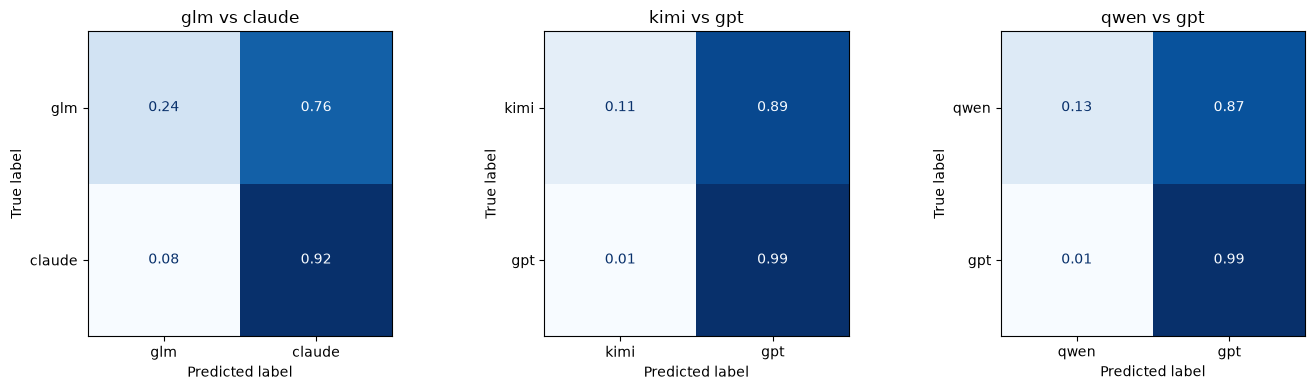

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (key, res) in zip(axes, pair_predictions.items()):
    labels = key.split("_vs_")
    cm = confusion_matrix(res["true"], res["pred"], labels=labels, normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(
        ax=ax, cmap="Blues", values_format=".2f", colorbar=False
    )
    ax.set_title(key.replace("_", " "))
plt.tight_layout()
plt.show()

## 3. Pairwise Discriminative N-grams

Inspect binary SVM coefficients for interpretation only; this is not held-out evaluation.

In [18]:
feature_rows = []
TOP_K = 15

for a, b in PAIRS:
    mask = y_family.isin([a, b])
    clf = build_char_model(class_weight="balanced")
    clf.fit(X[mask], y_family[mask])
    vec = clf.named_steps["tfidfvectorizer"]
    svc = clf.named_steps["linearsvc"]
    names = vec.get_feature_names_out()
    # For binary LinearSVC, coef_[0] supports classes_[1] when positive.
    weights = svc.coef_[0]
    negative_class, positive_class = svc.classes_
    for label, idxs, magnitude in [
        (positive_class, np.argsort(weights)[-TOP_K:][::-1], weights),
        (negative_class, np.argsort(weights)[:TOP_K], -weights),
    ]:
        for rank, j in enumerate(idxs, start=1):
            feature_rows.append({
                "pair": f"{a}_vs_{b}", "supports_family": label,
                "rank": rank, "ngram": repr(names[j]),
                "coefficient_magnitude": float(magnitude[j]),
            })

pair_features = pd.DataFrame(feature_rows)
for key in pair_features["pair"].unique():
    print("\n", key)
    display(pair_features[pair_features["pair"] == key]
            .pivot(index="rank", columns="supports_family", values="ngram"))


 glm_vs_claude


supports_family,claude,glm
rank,,
1,' —','; '
2,' — ',': '
3,'— ',' eve'
4,'sing ','ed t'
5,'d fo','sed t'
6,'d for',' ev'
7,'e of','e—'
8,'sing','—and'
9,'d in ','every'



 kimi_vs_gpt


supports_family,gpt,kimi
rank,,
1,"', but'","""'s"""
2,"', bu'","""'s """
3,'’s ','read '
4,'’s','s—'
5,'seem','breat'
6,' seem','reath'
7,'eem','e—'
8,'nea','tes t'
9,'fam','ot t'



 qwen_vs_gpt


supports_family,gpt,qwen
rank,,
1,': ',"', l'"
2,'’s',' whis'
3,'’s ','whis'
4,' its ','hispe'
5,'its ','hisp'
6,' “','whisp'
7,'its','nous'
8,'s—','isp'
9,' an ','tche'


## 4. Hierarchical Classification

Compare the flat 18-class baseline, family → subtype classification, and exploratory binary routing on the same GroupKFold splits. The binary gates are diagnostic and may be applied outside their training pair.

In [19]:
def fit_subtype_models(train_idx):
    """One subtype classifier per family, fitted only on outer-fold training data."""
    fitted = {}
    for family in family_names:
        family_idx = train_idx[y_family.iloc[train_idx].eq(family).to_numpy()]
        classes = sorted(y.iloc[family_idx].unique())
        if len(classes) == 1:
            fitted[family] = classes[0]  # Qwen and Kimi: one subtype.
        else:
            subtype = build_char_model()
            subtype.fit(X.iloc[family_idx], y.iloc[family_idx])
            fitted[family] = subtype
    return fitted


def subtype_predict(families, texts, subtype_models):
    out = np.empty(len(texts), dtype=object)
    fam_arr = np.asarray(families, dtype=object)
    for family in np.unique(fam_arr):
        idx = np.flatnonzero(fam_arr == family)
        model_or_label = subtype_models[family]
        if isinstance(model_or_label, str):
            out[idx] = model_or_label
        else:
            out[idx] = model_or_label.predict(texts.iloc[idx])
    return out


def gated_family_predictions(family_pred, texts, gates):
    refined = np.asarray(family_pred, dtype=object).copy()
    for i in range(len(refined)):
        if refined[i] == "claude":
            if gates["glm_vs_claude"].predict(texts.iloc[[i]])[0] == "glm":
                refined[i] = "glm"
        elif refined[i] == "gpt":
            qwen_vote = gates["qwen_vs_gpt"].predict(texts.iloc[[i]])[0] == "qwen"
            kimi_vote = gates["kimi_vs_gpt"].predict(texts.iloc[[i]])[0] == "kimi"
            if qwen_vote != kimi_vote:
                refined[i] = "qwen" if qwen_vote else "kimi"
    return refined


oof = {
    "flat": np.empty(len(y), dtype=object),
    "hierarchy": np.empty(len(y), dtype=object),
    "hierarchy_gated": np.empty(len(y), dtype=object),
}
family_oof = {key: np.empty(len(y), dtype=object) for key in ["hierarchy", "hierarchy_gated"]}

for fold_id, (train_idx, val_idx) in enumerate(folds):
    x_val = X.iloc[val_idx]

    flat = build_char_model()
    flat.fit(X.iloc[train_idx], y.iloc[train_idx])
    oof["flat"][val_idx] = flat.predict(x_val)

    family_clf = build_char_model(class_weight="balanced")
    family_clf.fit(X.iloc[train_idx], y_family.iloc[train_idx])
    base_family = family_clf.predict(x_val)

    gates = {}
    for a, b in PAIRS:
        pair_train = train_idx[y_family.iloc[train_idx].isin([a, b]).to_numpy()]
        gate = build_char_model(class_weight="balanced")
        gate.fit(X.iloc[pair_train], y_family.iloc[pair_train])
        gates[f"{a}_vs_{b}"] = gate

    refined_family = gated_family_predictions(base_family, x_val, gates)
    subtypes = fit_subtype_models(train_idx)

    family_oof["hierarchy"][val_idx] = base_family
    family_oof["hierarchy_gated"][val_idx] = refined_family
    oof["hierarchy"][val_idx] = subtype_predict(base_family, x_val, subtypes)
    oof["hierarchy_gated"][val_idx] = subtype_predict(refined_family, x_val, subtypes)
    print(f"Fold {fold_id + 1}/{len(folds)} completed")

result_rows = []
for name, pred in oof.items():
    result_rows.append({
        "system": name,
        "18_model_accuracy": accuracy_score(y, pred),
        "18_model_balanced_accuracy": balanced_accuracy_score(y, pred),
        "family_balanced_accuracy": balanced_accuracy_score(
            y_family, pd.Series(pred).map(get_family)
        ),
    })
results = pd.DataFrame(result_rows)
results["delta_balanced_vs_flat"] = (
    results["18_model_balanced_accuracy"]
    - results.loc[results["system"] == "flat", "18_model_balanced_accuracy"].iloc[0]
)
display(results.round(4))

Fold 1/5 completed
Fold 2/5 completed
Fold 3/5 completed
Fold 4/5 completed
Fold 5/5 completed


,system,18_model_accuracy,18_model_balanced_accuracy,family_balanced_accuracy,delta_balanced_vs_flat
0,flat,0.3157,0.3156,0.5248,0.0000
1,hierarchy,0.3123,0.3123,0.4937,-0.0033
2,hierarchy_gated,0.3112,0.3112,0.4975,-0.0044


### 4.1. Prediction Changes

Count corrected and newly introduced errors relative to the flat baseline.

In [20]:
comparison = pd.DataFrame({
    "true_model": y.to_numpy(),
    "true_family": y_family.to_numpy(),
    "flat": oof["flat"],
    "hierarchy": oof["hierarchy"],
    "hierarchy_gated": oof["hierarchy_gated"],
})
for system in ["hierarchy", "hierarchy_gated"]:
    comparison[f"{system}_fixed"] = (
        comparison["flat"].ne(comparison["true_model"])
        & comparison[system].eq(comparison["true_model"])
    )
    comparison[f"{system}_broken"] = (
        comparison["flat"].eq(comparison["true_model"])
        & comparison[system].ne(comparison["true_model"])
    )

change_summary = pd.DataFrame({
    name: {
        "fixed_vs_flat": int(comparison[f"{name}_fixed"].sum()),
        "broken_vs_flat": int(comparison[f"{name}_broken"].sum()),
    }
    for name in ["hierarchy", "hierarchy_gated"]
}).T
change_summary["net_change"] = change_summary["fixed_vs_flat"] - change_summary["broken_vs_flat"]
display(change_summary)

per_model = pd.DataFrame({"model": model_names})
for system, pred in oof.items():
    per_model[system] = [
        np.mean(pred[y.eq(model).to_numpy()] == model)
        for model in model_names
    ]
per_model["gated_minus_flat"] = per_model["hierarchy_gated"] - per_model["flat"]
display(per_model.sort_values("gated_minus_flat").round(3))

,fixed_vs_flat,broken_vs_flat,net_change
hierarchy,171,180,-9
hierarchy_gated,171,183,-12


,model,flat,hierarchy,hierarchy_gated,gated_minus_flat
17,qwen3.8-max,0.293,0.107,0.120,-0.173
16,kimi-k3,0.220,0.047,0.053,-0.167
3,claude-opus-5,0.627,0.600,0.567,-0.060
10,glm-5.3-flash,0.167,0.100,0.113,-0.053
1,claude-opus-4-6,0.413,0.373,0.367,-0.047
9,glm-5.3,0.147,0.100,0.113,-0.033
7,gemini-3.7-flash,0.393,0.367,0.367,-0.027
14,gpt-5.6-terra,0.253,0.240,0.240,-0.013
5,gemini-3.1-pro-preview,0.733,0.720,0.720,-0.013
4,claude-sonnet-5,0.233,0.260,0.253,0.020


## 5. Initial Results

| Method | Balanced accuracy (18 classes) |
|---|---:|
| Flat LinearSVC | **31.56%** |
| Family → Subtype | 31.23% |
| Hierarchy + Binary Gates | 31.12% |

Hard routing did not improve accuracy. Binary pairwise performance was only slightly above chance, and incorrect family selection blocked subtype prediction.

## 6. Soft Hierarchy (Exploratory)

Combine family and subtype SVM scores without restricting prediction to one family. Softmax-transformed scores are **not calibrated probabilities**. Evaluate on the same held-out prompt folds.

In [21]:
from scipy.special import softmax

# A fixed, exploratory softmax temperature. No tuning on the outer test folds.
TEMPERATURE = 1.0


def class_score_matrix(clf, texts):
    """Return decision scores with one column for each class."""
    svc = clf.named_steps["linearsvc"]
    scores = np.asarray(clf.decision_function(texts))
    if len(svc.classes_) == 2:
        # Binary LinearSVC returns a single margin for classes_[1].
        scores = np.column_stack([-scores.ravel(), scores.ravel()])
    return scores, np.asarray(svc.classes_, dtype=object)


def soft_hierarchy_predict(texts, family_model, subtype_models, temperature=1.0):
    family_scores, families = class_score_matrix(family_model, texts)
    family_weights = softmax(family_scores / temperature, axis=1)

    scores_by_model = {}
    for family_index, family in enumerate(families):
        subtype = subtype_models[family]
        if isinstance(subtype, str):
            # Only one possible model in this family.
            scores_by_model[subtype] = family_weights[:, family_index]
        else:
            subtype_scores, subtypes = class_score_matrix(subtype, texts)
            subtype_weights = softmax(subtype_scores / temperature, axis=1)
            for subtype_index, model_name in enumerate(subtypes):
                scores_by_model[model_name] = (
                    family_weights[:, family_index]
                    * subtype_weights[:, subtype_index]
                )

    model_labels = sorted(scores_by_model)
    joint_scores = np.column_stack([scores_by_model[name] for name in model_labels])
    assert np.allclose(joint_scores.sum(axis=1), 1.0, atol=1e-6)
    return np.asarray(model_labels, dtype=object)[joint_scores.argmax(axis=1)]


soft_oof = np.empty(len(y), dtype=object)
soft_fold_rows = []

for fold_id, (train_idx, val_idx) in enumerate(folds):
    family_clf = build_char_model(class_weight="balanced")
    family_clf.fit(X.iloc[train_idx], y_family.iloc[train_idx])
    subtype_models = fit_subtype_models(train_idx)

    predictions_soft = soft_hierarchy_predict(
        X.iloc[val_idx], family_clf, subtype_models, TEMPERATURE
    )
    soft_oof[val_idx] = predictions_soft
    soft_fold_rows.append({
        "fold": fold_id + 1,
        "flat_balanced_accuracy": balanced_accuracy_score(
            y.iloc[val_idx], oof["flat"][val_idx]
        ),
        "hard_balanced_accuracy": balanced_accuracy_score(
            y.iloc[val_idx], oof["hierarchy"][val_idx]
        ),
        "soft_balanced_accuracy": balanced_accuracy_score(
            y.iloc[val_idx], predictions_soft
        ),
    })

soft_results = []
for name, pred in [
    ("flat", oof["flat"]),
    ("hard_hierarchy", oof["hierarchy"]),
    ("hard_binary_gates", oof["hierarchy_gated"]),
    ("soft_hierarchy", soft_oof),
]:
    soft_results.append({
        "system": name,
        "accuracy": accuracy_score(y, pred),
        "balanced_accuracy": balanced_accuracy_score(y, pred),
        "family_balanced_accuracy": balanced_accuracy_score(
            y_family, pd.Series(pred).map(get_family)
        ),
    })

soft_results = pd.DataFrame(soft_results)
soft_results["delta_vs_flat"] = (
    soft_results["balanced_accuracy"]
    - soft_results.loc[soft_results["system"] == "flat", "balanced_accuracy"].iloc[0]
)
display(soft_results.round(4))
display(pd.DataFrame(soft_fold_rows).round(4))

,system,accuracy,balanced_accuracy,family_balanced_accuracy,delta_vs_flat
0,flat,0.3157,0.3156,0.5248,0.0000
1,hard_hierarchy,0.3123,0.3123,0.4937,-0.0033
2,hard_binary_gates,0.3112,0.3112,0.4975,-0.0044
3,soft_hierarchy,0.1738,0.1737,0.3747,-0.1419


,fold,flat_balanced_accuracy,hard_balanced_accuracy,soft_balanced_accuracy
0,1,0.3019,0.3074,0.1704
1,2,0.2944,0.2704,0.1704
2,3,0.3259,0.3204,0.1648
3,4,0.3278,0.3222,0.1759
4,5,0.3281,0.3411,0.1870


### 6.1. Prediction Changes

Compare corrected errors, new errors, and per-model recall with the flat baseline.

In [22]:
true = y.to_numpy()
flat_pred = oof["flat"]

fixed = (flat_pred != true) & (soft_oof == true)
broken = (flat_pred == true) & (soft_oof != true)

print(f"Fixed by soft hierarchy: {fixed.sum()}")
print(f"Broken by soft hierarchy: {broken.sum()}")
print(f"Net correct predictions: {fixed.sum() - broken.sum():+d}")

per_model_soft = pd.DataFrame({
    "model": model_names,
    "flat_recall": [np.mean(flat_pred[y.eq(m).to_numpy()] == m) for m in model_names],
    "soft_recall": [np.mean(soft_oof[y.eq(m).to_numpy()] == m) for m in model_names],
})
per_model_soft["delta_recall"] = per_model_soft["soft_recall"] - per_model_soft["flat_recall"]
display(per_model_soft.sort_values("delta_recall").round(3))

Fixed by soft hierarchy: 154
Broken by soft hierarchy: 537
Net correct predictions: -383


,model,flat_recall,soft_recall,delta_recall
3,claude-opus-5,0.627,0.067,-0.560
1,claude-opus-4-6,0.413,0.020,-0.393
15,gpt-6-astra,0.480,0.093,-0.387
11,gpt-5.5,0.267,0.000,-0.267
2,claude-opus-4-8,0.240,0.007,-0.233
4,claude-sonnet-5,0.233,0.000,-0.233
14,gpt-5.6-terra,0.253,0.027,-0.227
12,gpt-5.6-luna,0.260,0.040,-0.220
5,gemini-3.1-pro-preview,0.733,0.547,-0.187
13,gpt-5.6-sol,0.147,0.000,-0.147


## 7. Conclusions

| Method | Balanced accuracy (18 classes) |
|---|---:|
| Flat LinearSVC | **31.56%** |
| Hard hierarchy | 31.23% |
| Hard hierarchy + binary gates | 31.12% |
| Soft hierarchy | 17.37% |

**Family-first classification did not improve 18-model attribution.** Hard routing lost correct predictions due to family errors; the soft-score heuristic favored single-model families and reduced overall accuracy. Flat LinearSVC remains the best tested approach. Future work may test calibrated score fusion using nested validation.